In [1]:
import torch
import numpy as np
import pandas as pd

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU available: True
Tesla T4


Dataset Exploration & Preprocessing

In [2]:
import os
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
sample_df = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

print("Train shape:", train_df.shape)
print("Train columns:", train_df.columns.tolist())
print("\nFirst 3 training rows:")
display(train_df.head(3))

print("\nSample submission columns:", sample_df.columns.tolist())
print("Sample submission shape:", sample_df.shape)
display(sample_df.head(3))


Train shape: (13673, 2)
Train columns: ['image_id', 'label']

First 3 training rows:


,image_id,label
0,8f094b3580.png,6
1,4ab7018005.png,2
2,6b5413214b.png,5



Sample submission columns: ['image_id', 'label']
Sample submission shape: (3419, 2)


,image_id,label
0,32630ef937.png,0
1,136affd755.png,0
2,391203af62.png,0


In [3]:
import os
from collections import Counter

DATA_DIR = "/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment"

file_counts = Counter()
image_paths = []
other_files = []

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

for root, dirs, files in os.walk(DATA_DIR):
    for filename in files:
        path = os.path.join(root, filename)
        ext = os.path.splitext(filename)[1].lower()
        file_counts[ext or "[no extension]"] += 1

        if ext in image_extensions:
            if len(image_paths) < 10:
                image_paths.append(path)
        elif ext != ".csv" and len(other_files) < 10:
            other_files.append(path)

print("File counts by extension:")
for ext, count in file_counts.items():
    print(f"{ext}: {count}")

print("\nSample image paths:")
for path in image_paths:
    print(path)

print("\nOther file examples:")
for path in other_files:
    print(path)


File counts by extension:
.csv: 2
.png: 17092

Sample image paths:
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/9d3d66b415.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/71971a30ad.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/5001bb3efd.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/5565ae19aa.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/c92f81b83c.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/8fd5b82b0d.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/10cc216f0f.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/5c7644ad77.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/b9a963a187.png
/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment/test/c8845a3542.png

Other file examples:


Number of classes: 8

Samples per class:
label
0     974
1    2494
2    1241
3    2316
4     971
5    1136
6    2663
7    1878
Name: count, dtype: int64

Missing labels: 0


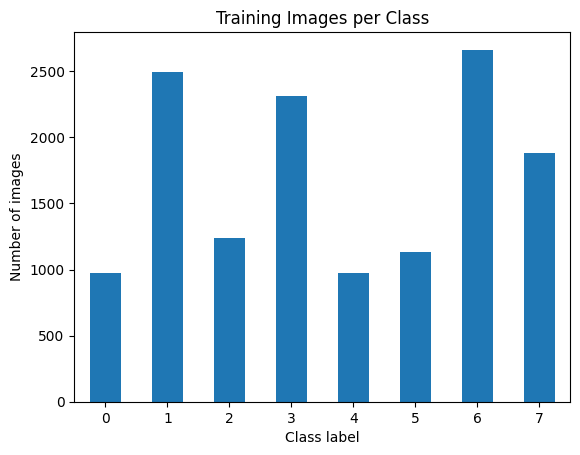

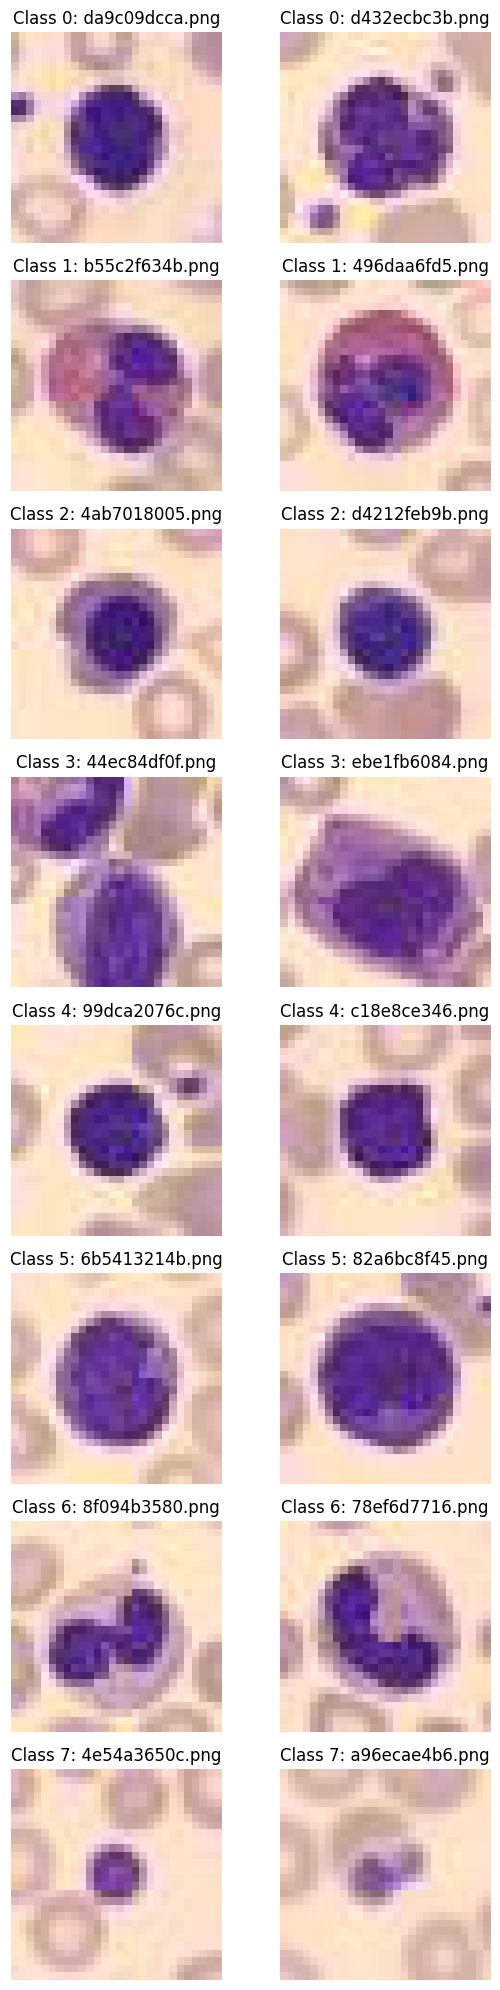

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment"
TRAIN_DIR = os.path.join(DATA_DIR, "train")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

# Count samples in each class
class_counts = train_df["label"].value_counts().sort_index()

print("Number of classes:", train_df["label"].nunique())
print("\nSamples per class:")
print(class_counts)
print("\nMissing labels:", train_df["label"].isna().sum())

# Plot class distribution
class_counts.plot(kind="bar")
plt.title("Training Images per Class")
plt.xlabel("Class label")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

# Display 2 example images from each class
fig, axes = plt.subplots(8, 2, figsize=(6, 20))

for label in range(8):
    examples = train_df[train_df["label"] == label].head(2)

    for j, (_, row) in enumerate(examples.iterrows()):
        ax = axes[label, j]

        if len(examples) > j:
            image_path = os.path.join(TRAIN_DIR, row["image_id"])
            image = Image.open(image_path).convert("RGB")

            ax.imshow(image)
            ax.set_title(f"Class {label}: {row['image_id']}")
        ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:
from sklearn.model_selection import train_test_split

# Separate image names and their labels
X = train_df["image_id"]
y = train_df["label"]

# Split the data: 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val.value_counts().sort_index())


Training images: 10938
Validation images: 2735

Training class distribution:
label
0     779
1    1995
2     993
3    1853
4     777
5     909
6    2130
7    1502
Name: count, dtype: int64

Validation class distribution:
label
0    195
1    499
2    248
3    463
4    194
5    227
6    533
7    376
Name: count, dtype: int64


In [6]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

DATA_DIR = "/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment"
TRAIN_DIR = os.path.join(DATA_DIR, "train")

# Convert each image into a PyTorch tensor
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])


class BloodCellDataset(Dataset):
    def __init__(self, image_ids, labels=None, transform=None):
        self.image_ids = list(image_ids)
        self.labels = list(labels) if labels is not None else None
        self.transform = transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image_path = os.path.join(TRAIN_DIR, image_id)

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.labels is not None:
            label = int(self.labels[index])
            return image, label

        return image


# Create datasets
train_dataset = BloodCellDataset(
    X_train, y_train, transform
)

val_dataset = BloodCellDataset(
    X_val, y_val, transform
)

# Create data loaders

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 171
Validation batches: 43


In [7]:
# Test data paths
TEST_DIR = os.path.join(DATA_DIR, "test")

# Use the IDs in the submission template to preserve the correct order
test_image_ids = sample_df["image_id"].tolist()

# Create a separate dataset for test images
class BloodCellTestDataset(Dataset):
    def __init__(self, image_ids, transform=None):
        self.image_ids = list(image_ids)
        self.transform = transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image_path = os.path.join(TEST_DIR, image_id)

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image


test_dataset = BloodCellTestDataset(
    test_image_ids,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("First test IDs:", test_image_ids[:5])


Test images: 3419
Test batches: 54
First test IDs: ['32630ef937.png', '136affd755.png', '391203af62.png', '78bfaa91c3.png', '1a47dc97ba.png']


In [8]:
test_batch = next(iter(test_loader))

print("Batch shape:", test_batch.shape)
print("Expected image shape: [batch_size, 3, 28, 28]")
print("Number of test images:", len(test_dataset))

assert len(test_dataset) == len(sample_df)
assert test_batch.ndim == 4
assert test_batch.shape[1:] == (3, 28, 28)

print("Test dataset is ready!")


Batch shape: torch.Size([64, 3, 28, 28])
Expected image shape: [batch_size, 3, 28, 28]
Number of test images: 3419
Test dataset is ready!


In [9]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image values range:",
      images.min().item(), "to", images.max().item())
print("First 10 labels:", labels[:10].tolist())

print("GPU available:", torch.cuda.is_available())


Images shape: torch.Size([64, 3, 28, 28])
Labels shape: torch.Size([64])
Image values range: -0.9058823585510254 to 1.0
First 10 labels: [7, 2, 1, 3, 1, 5, 4, 6, 6, 6]
GPU available: True


Baseline CNN

In [10]:
import torch
import torch.nn as nn

class BloodCellCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 3 x 28 x 28 -> 32 x 14 x 14
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2: 32 x 14 x 14 -> 64 x 7 x 7
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3: 64 x 7 x 7 -> 128 x 3 x 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BloodCellCNN().to(device)

print(model)

BloodCellCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, di

In [11]:

images, labels = next(iter(train_loader))

images = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Predicted classes:", outputs.argmax(dim=1)[:10].tolist())


Input shape: torch.Size([64, 3, 28, 28])
Output shape: torch.Size([64, 8])
Predicted classes: [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]


In [12]:
import torch.nn as nn
import torch.optim as optim
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [13]:
import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

EPOCHS = 15
best_val_acc = 0.0
history = []

for epoch in range(EPOCHS):
    #Training phase
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation phase

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss /= val_total
    val_acc = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    # Save the best model according to validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            model.state_dict(),
            "/kaggle/working/best_bloodcell_cnn.pth"
        )

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

print(f"\nBest Validation Accuracy: {best_val_acc:.2%}")


Epoch [1/15] | Train Loss: 0.5261 | Train Acc: 81.82% | Val Loss: 0.4808 | Val Acc: 82.34%
Epoch [2/15] | Train Loss: 0.3047 | Train Acc: 89.18% | Val Loss: 0.4748 | Val Acc: 82.27%
Epoch [3/15] | Train Loss: 0.2431 | Train Acc: 91.16% | Val Loss: 0.3665 | Val Acc: 86.98%
Epoch [4/15] | Train Loss: 0.2074 | Train Acc: 92.79% | Val Loss: 0.4669 | Val Acc: 84.13%
Epoch [5/15] | Train Loss: 0.1789 | Train Acc: 93.80% | Val Loss: 0.2839 | Val Acc: 90.53%
Epoch [6/15] | Train Loss: 0.1529 | Train Acc: 94.78% | Val Loss: 0.1866 | Val Acc: 93.31%
Epoch [7/15] | Train Loss: 0.1417 | Train Acc: 94.97% | Val Loss: 0.1909 | Val Acc: 93.46%
Epoch [8/15] | Train Loss: 0.1306 | Train Acc: 95.36% | Val Loss: 0.2294 | Val Acc: 91.99%
Epoch [9/15] | Train Loss: 0.1116 | Train Acc: 96.01% | Val Loss: 0.2710 | Val Acc: 91.70%
Epoch [10/15] | Train Loss: 0.1043 | Train Acc: 96.51% | Val Loss: 0.2389 | Val Acc: 92.58%
Epoch [11/15] | Train Loss: 0.0927 | Train Acc: 96.79% | Val Loss: 0.1688 | Val Acc: 94.6

In [14]:
import numpy as np
import torch
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Load the best saved model
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_bloodcell_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Validation Accuracy:",
      f"{accuracy_score(all_labels, all_preds):.2%}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(8)),
    zero_division=0,
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(8))
))


Validation Accuracy: 94.63%

Classification Report:
              precision    recall  f1-score   support

           0     0.9665    0.8872    0.9251       195
           1     0.9803    0.9960    0.9881       499
           2     0.9139    0.9839    0.9476       248
           3     0.8552    0.9309    0.8914       463
           4     0.9880    0.8454    0.9111       194
           5     0.8707    0.8899    0.8802       227
           6     0.9941    0.9418    0.9672       533
           7     1.0000    0.9973    0.9987       376

    accuracy                         0.9463      2735
   macro avg     0.9461    0.9340    0.9387      2735
weighted avg     0.9489    0.9463    0.9465      2735


Confusion Matrix:
[[173   4   0  12   2   4   0   0]
 [  0 497   0   2   0   0   0   0]
 [  1   0 244   2   0   0   1   0]
 [  3   2   4 431   0  21   2   0]
 [  2   1  14  11 164   2   0   0]
 [  0   1   1  23   0 202   0   0]
 [  0   2   3  23   0   3 502   0]
 [  0   0   1   0   0   0   0 375

Class 3 images misclassified as 0, 5, or 6: 26


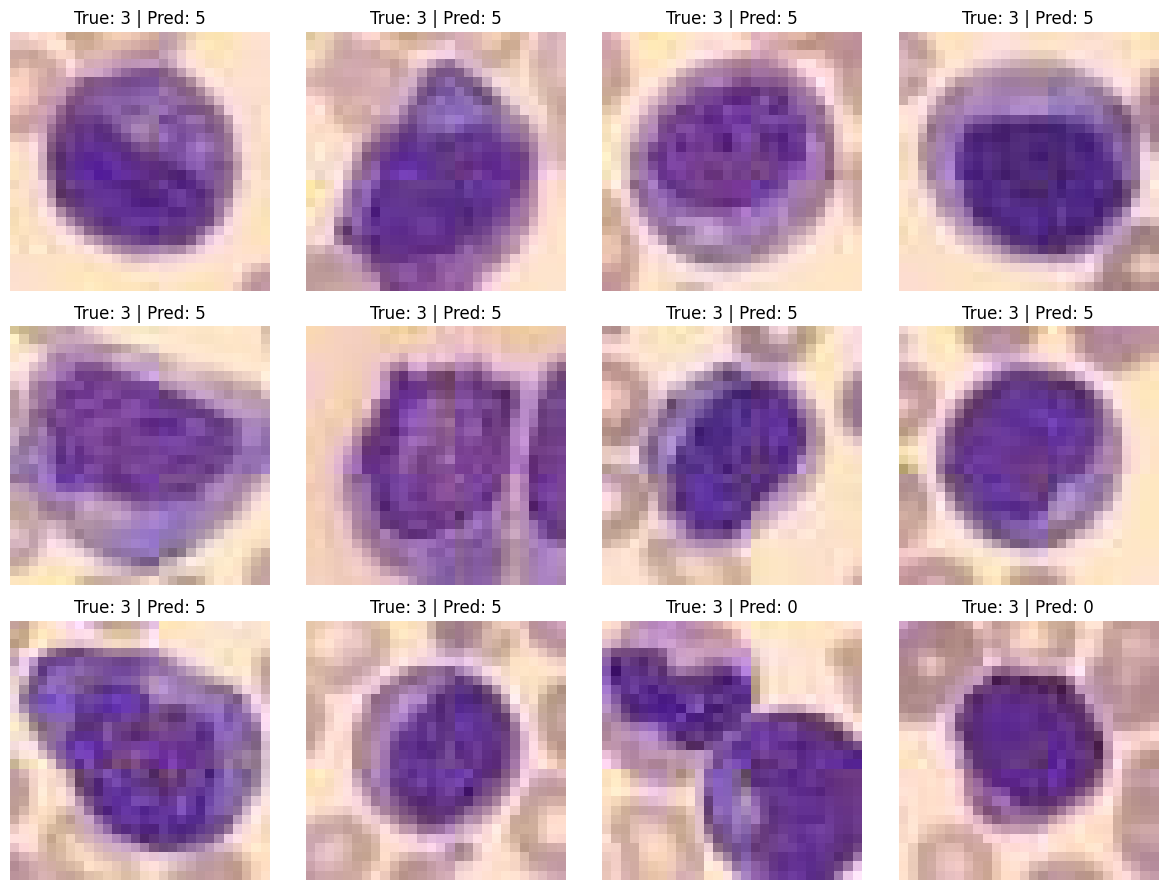

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os

# Match predictions with the validation image IDs
val_results = pd.DataFrame({
    "image_id": list(X_val),
    "true_label": list(y_val),
    "pred_label": all_preds
})

# Focus on the most frequent Class 3 mistakes
mistakes = val_results[
    (val_results["true_label"] == 3) &
    (val_results["pred_label"].isin([0, 5, 6]))
]

print("Class 3 images misclassified as 0, 5, or 6:",
      len(mistakes))

# Display up to 12 misclassified images
examples = mistakes.head(12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for ax, (_, row) in zip(axes, examples.iterrows()):
    image_path = os.path.join(TRAIN_DIR, row["image_id"])
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"True: {row['true_label']} | Pred: {row['pred_label']}"
    )
    ax.axis("off")

for ax in axes[len(examples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:
import os
import shutil

BASELINE_PATH = "/kaggle/working/baseline_bloodcell_cnn.pth"
CURRENT_PATH = "/kaggle/working/best_bloodcell_cnn.pth"

assert os.path.exists(CURRENT_PATH), "Best model file not found!"

shutil.copy2(CURRENT_PATH, BASELINE_PATH)

print("Baseline model saved:", BASELINE_PATH)
print("File size:",
      round(os.path.getsize(BASELINE_PATH) / (1024**2), 2),
      "MB")


Baseline model saved: /kaggle/working/baseline_bloodcell_cnn.pth
File size: 1.12 MB


In [17]:
import os
import shutil

BASELINE_PATH = "/kaggle/working/baseline_bloodcell_cnn.pth"
CURRENT_PATH = "/kaggle/working/best_bloodcell_cnn.pth"

assert os.path.exists(CURRENT_PATH), "Best model file not found!"

shutil.copy2(CURRENT_PATH, BASELINE_PATH)

print("Baseline model saved:", BASELINE_PATH)
print("File size:",
      round(os.path.getsize(BASELINE_PATH) / (1024**2), 2),
      "MB")


Baseline model saved: /kaggle/working/baseline_bloodcell_cnn.pth
File size: 1.12 MB


In [18]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/baseline_bloodcell_cnn.pth"
))

/kaggle/working/baseline_bloodcell_cnn.pth

In [19]:
model = BloodCellCNN().to(device)

model.load_state_dict(
    torch.load(
        "baseline_bloodcell_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

BloodCellCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, di

In [20]:
import os

BASELINE_PATH = "/kaggle/working/baseline_bloodcell_cnn.pth"

print("Baseline exists:", os.path.exists(BASELINE_PATH))

if os.path.exists(BASELINE_PATH):
    print("File size:", round(os.path.getsize(BASELINE_PATH) / (1024**2), 2), "MB")

Baseline exists: True
File size: 1.12 MB


Class Weights Experiment

In [21]:
print("X_train:", len(X_train))
print("X_val:", len(X_val))
print("y_train:", len(y_train))
print("y_val:", len(y_val))

X_train: 10938
X_val: 2735
y_train: 10938
y_val: 2735


In [22]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(8)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.array(y_train)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

for cls, weight in enumerate(class_weights.cpu().tolist()):
    print(f"Class {cls}: {weight:.3f}")

Class 0: 1.755
Class 1: 0.685
Class 2: 1.377
Class 3: 0.738
Class 4: 1.760
Class 5: 1.504
Class 6: 0.642
Class 7: 0.910


In [23]:
class_weights_model = BloodCellCNN().to(device)

# Use class-weighted CrossEntropyLoss
class_weights_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

class_weights_optimizer = torch.optim.AdamW(
    class_weights_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("New model created successfully!")
print("Device:", device)
print("Class-weighted loss is ready!")

New model created successfully!
Device: cuda
Class-weighted loss is ready!


In [24]:
import copy
import torch

CW_EPOCHS = 15
cw_best_val_acc = 0.0
cw_history = []

CW_BEST_PATH = "/kaggle/working/class_weights_best.pth"

for epoch in range(CW_EPOCHS):
    #Training
    class_weights_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        class_weights_optimizer.zero_grad(set_to_none=True)

        outputs = class_weights_model(images)
        loss = class_weights_criterion(outputs, labels)

        loss.backward()
        class_weights_optimizer.step()

        batch_size = labels.size(0)
        train_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss /= train_total
    train_acc = train_correct / train_total

    #Validation
    class_weights_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = class_weights_model(images)
            loss = class_weights_criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss /= val_total
    val_acc = val_correct / val_total

    cw_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    # Save the best checkpoint based on validation accuracy
    if val_acc > cw_best_val_acc:
        cw_best_val_acc = val_acc
        torch.save(
            class_weights_model.state_dict(),
            CW_BEST_PATH
        )

    print(
        f"Epoch {epoch + 1:02d}/{CW_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}%"
    )

print("\nClass Weights Experiment Finished!")
print(f"Best Validation Accuracy: {cw_best_val_acc * 100:.2f}%")
print(f"Best model saved to: {CW_BEST_PATH}")


Epoch 01/15 | Train Loss: 0.5707 | Train Acc: 81.33% | Val Loss: 0.5244 | Val Acc: 85.63%
Epoch 02/15 | Train Loss: 0.3553 | Train Acc: 87.95% | Val Loss: 0.4711 | Val Acc: 80.66%
Epoch 03/15 | Train Loss: 0.2575 | Train Acc: 91.35% | Val Loss: 0.4524 | Val Acc: 82.16%
Epoch 04/15 | Train Loss: 0.2123 | Train Acc: 92.27% | Val Loss: 0.3633 | Val Acc: 88.08%
Epoch 05/15 | Train Loss: 0.2082 | Train Acc: 92.74% | Val Loss: 0.2920 | Val Acc: 87.97%
Epoch 06/15 | Train Loss: 0.1727 | Train Acc: 94.08% | Val Loss: 0.5038 | Val Acc: 85.05%
Epoch 07/15 | Train Loss: 0.1602 | Train Acc: 94.57% | Val Loss: 0.1962 | Val Acc: 93.16%
Epoch 08/15 | Train Loss: 0.1319 | Train Acc: 95.17% | Val Loss: 0.2144 | Val Acc: 91.30%
Epoch 09/15 | Train Loss: 0.1159 | Train Acc: 95.96% | Val Loss: 0.1716 | Val Acc: 94.99%
Epoch 10/15 | Train Loss: 0.1213 | Train Acc: 95.68% | Val Loss: 0.3157 | Val Acc: 89.87%
Epoch 11/15 | Train Loss: 0.1030 | Train Acc: 96.37% | Val Loss: 0.1828 | Val Acc: 93.53%
Epoch 12/1

In [25]:
from sklearn.metrics import classification_report, confusion_matrix
import torch
import numpy as np

# Load the best Class Weights checkpoint
class_weights_model.load_state_dict(
    torch.load(
        "/kaggle/working/class_weights_best.pth",
        map_location=device,
        weights_only=True
    )
)

class_weights_model.eval()

cw_preds = []
cw_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = class_weights_model(images)
        predictions = outputs.argmax(dim=1)

        cw_preds.extend(predictions.cpu().numpy())
        cw_labels.extend(labels.numpy())

print("Validation Accuracy:",
      f"{np.mean(np.array(cw_preds) == np.array(cw_labels)) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(cw_labels, cw_preds, digits=4))

print("\nConfusion Matrix:")
print(confusion_matrix(cw_labels, cw_preds))


Validation Accuracy: 94.99%

Classification Report:
              precision    recall  f1-score   support

           0     0.9113    0.9487    0.9296       195
           1     0.9980    0.9840    0.9909       499
           2     0.8945    0.9919    0.9407       248
           3     0.8842    0.9071    0.8955       463
           4     0.9780    0.9175    0.9468       194
           5     0.9091    0.8370    0.8716       227
           6     0.9790    0.9606    0.9697       533
           7     1.0000    1.0000    1.0000       376

    accuracy                         0.9499      2735
   macro avg     0.9443    0.9434    0.9431      2735
weighted avg     0.9509    0.9499    0.9499      2735


Confusion Matrix:
[[185   0   0   5   3   2   0   0]
 [  0 491   1   4   0   0   3   0]
 [  0   0 246   1   0   0   1   0]
 [  9   1  12 420   0  15   6   0]
 [  3   0   8   3 178   1   1   0]
 [  6   0   4  26   1 190   0   0]
 [  0   0   4  16   0   1 512   0]
 [  0   0   0   0   0   0   0 376

In [26]:
import os
import shutil

BACKUP_DIR = "/kaggle/working/model_backups"
os.makedirs(BACKUP_DIR, exist_ok=True)

files_to_backup = [
    "baseline_bloodcell_cnn.pth",
    "class_weights_best.pth",
    "experiment_results.json"
]

for filename in files_to_backup:
    source = f"/kaggle/working/{filename}"

    if os.path.exists(source):
        destination = os.path.join(BACKUP_DIR, filename)
        shutil.copy2(source, destination)
        print(f"Backed up: {filename}")
    else:
        print(f"Not found: {filename}")

Backed up: baseline_bloodcell_cnn.pth
Backed up: class_weights_best.pth
Not found: experiment_results.json


In [27]:
import json
import os

results = {
    "baseline": {
        "best_val_accuracy": 93.27,
        "class_3_recall": 72.79,
        "macro_f1": 92.61
    },
    "class_weights": {
        "best_val_accuracy": 93.93,
        "class_3_recall": 83.15,
        "macro_f1": 93.32
    }
}

RESULTS_PATH = "/kaggle/working/experiment_results.json"

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

print("Results saved:", RESULTS_PATH)

Results saved: /kaggle/working/experiment_results.json


In [28]:
import os

files_to_check = [
    "/kaggle/working/baseline_bloodcell_cnn.pth",
    "/kaggle/working/class_weights_best.pth",
    "/kaggle/working/experiment_results.json"
]

for path in files_to_check:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"Saved: {os.path.basename(path)} | {size_mb:.2f} MB")
    else:
        print(f"Missing: {path}")

Saved: baseline_bloodcell_cnn.pth | 1.12 MB
Saved: class_weights_best.pth | 1.12 MB
Saved: experiment_results.json | 0.00 MB


In [29]:
from IPython.display import FileLink, display

for filename in [
    "baseline_bloodcell_cnn.pth",
    "class_weights_best.pth",
    "experiment_results.json"
]:
    path = f"/kaggle/working/{filename}"
    display(FileLink(path))

/kaggle/working/baseline_bloodcell_cnn.pth

/kaggle/working/class_weights_best.pth

/kaggle/working/experiment_results.json

Data Augmentation Experiment

In [30]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Augmentation for training images only
train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=15),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Validation images remain unchanged
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

aug_train_dataset = BloodCellDataset(
    X_train, y_train, train_transform
)

aug_val_dataset = BloodCellDataset(
    X_val, y_val, val_transform
)

aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

aug_val_loader = DataLoader(
    aug_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(aug_train_dataset))
print("Validation images:", len(aug_val_dataset))


Training images: 10938
Validation images: 2735


In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
import os

# Create a completely new model
augmentation_model = BloodCellCNN(num_classes=8).to(device)

# Same loss function as the baseline experiment
augmentation_criterion = nn.CrossEntropyLoss()

# New optimizer for the new model
augmentation_optimizer = optim.AdamW(
    augmentation_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Separate checkpoint path: old models won't be overwritten
AUGMENTATION_PATH = "/kaggle/working/augmentation_best.pth"

print("New augmentation model is ready!")
print("Device:", device)
print("Checkpoint path:", AUGMENTATION_PATH)


New augmentation model is ready!
Device: cuda
Checkpoint path: /kaggle/working/augmentation_best.pth


In [32]:
import copy

NUM_EPOCHS = 15
best_aug_accuracy = 0.0
best_aug_epoch = 0
augmentation_history = []

for epoch in range(NUM_EPOCHS):

    # Training 
    augmentation_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        augmentation_optimizer.zero_grad()

        outputs = augmentation_model(images)
        loss = augmentation_criterion(outputs, labels)

        loss.backward()
        augmentation_optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation
    augmentation_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = augmentation_model(images)
            loss = augmentation_criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    augmentation_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    # Save only when validation accuracy improves
    if val_accuracy > best_aug_accuracy:
        best_aug_accuracy = val_accuracy
        best_aug_epoch = epoch + 1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": augmentation_model.state_dict(),
            "optimizer_state_dict": augmentation_optimizer.state_dict(),
            "val_accuracy": val_accuracy
        }, AUGMENTATION_PATH)

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("\nTraining finished!")
print(f"Best Validation Accuracy: {best_aug_accuracy:.2f}%")
print(f"Best Epoch: {best_aug_epoch}")
print(f"Saved model: {AUGMENTATION_PATH}")


Epoch [01/15] Train Loss: 0.5361 | Train Acc: 80.96% | Val Loss: 0.4259 | Val Acc: 82.16%
Epoch [02/15] Train Loss: 0.3353 | Train Acc: 87.77% | Val Loss: 0.8856 | Val Acc: 71.48%
Epoch [03/15] Train Loss: 0.2720 | Train Acc: 90.23% | Val Loss: 0.3036 | Val Acc: 89.43%
Epoch [04/15] Train Loss: 0.2327 | Train Acc: 91.79% | Val Loss: 0.5745 | Val Acc: 81.90%
Epoch [05/15] Train Loss: 0.2102 | Train Acc: 92.73% | Val Loss: 0.2241 | Val Acc: 92.65%
Epoch [06/15] Train Loss: 0.1937 | Train Acc: 93.14% | Val Loss: 0.1675 | Val Acc: 93.82%
Epoch [07/15] Train Loss: 0.1808 | Train Acc: 93.71% | Val Loss: 0.3376 | Val Acc: 88.59%
Epoch [08/15] Train Loss: 0.1703 | Train Acc: 93.73% | Val Loss: 0.1994 | Val Acc: 93.56%
Epoch [09/15] Train Loss: 0.1611 | Train Acc: 94.21% | Val Loss: 0.2428 | Val Acc: 91.77%
Epoch [10/15] Train Loss: 0.1462 | Train Acc: 94.71% | Val Loss: 0.1948 | Val Acc: 93.38%
Epoch [11/15] Train Loss: 0.1381 | Train Acc: 95.34% | Val Loss: 0.1734 | Val Acc: 94.19%
Epoch [12/

In [33]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

checkpoint = torch.load(
    AUGMENTATION_PATH,
    map_location=device
)

augmentation_model.load_state_dict(
    checkpoint["model_state_dict"]
)
augmentation_model.eval()

# Collect predictions on validation data
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        outputs = augmentation_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Validation accuracy: {100 * np.mean(np.array(all_predictions) == np.array(all_labels)):.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))


Best checkpoint epoch: 14
Validation accuracy: 95.06%

Classification Report:
              precision    recall  f1-score   support

           0     0.9878    0.8308    0.9025       195
           1     1.0000    0.9860    0.9929       499
           2     0.9757    0.9718    0.9737       248
           3     0.8784    0.9050    0.8915       463
           4     0.9310    0.9742    0.9521       194
           5     0.8353    0.9383    0.8838       227
           6     0.9750    0.9531    0.9639       533
           7     1.0000    1.0000    1.0000       376

    accuracy                         0.9506      2735
   macro avg     0.9479    0.9449    0.9451      2735
weighted avg     0.9529    0.9506    0.9509      2735

Confusion Matrix:
[[162   0   0  15   9   9   0   0]
 [  0 492   1   4   0   0   2   0]
 [  0   0 241   1   2   1   3   0]
 [  2   0   2 419   2  30   8   0]
 [  0   0   1   3 189   1   0   0]
 [  0   0   2  11   1 213   0   0]
 [  0   0   0  24   0   1 508   0]
 [  0   

In [34]:
import json
import os

results = {
    "baseline": {
        "best_val_accuracy": 93.27,
        "macro_f1": 92.61,
        "class_0_recall": 95.38,
        "class_3_recall": 72.79,
        "class_5_recall": 93.39
    },
    "class_weights": {
        "best_val_accuracy": 93.93,
        "macro_f1": 93.32,
        "class_0_recall": 92.82,
        "class_3_recall": 83.15,
        "class_5_recall": 89.43
    },
    "augmentation": {
        "best_val_accuracy": 94.63,
        "macro_f1": 93.97,
        "class_0_recall": 80.00,
        "class_3_recall": 88.55,
        "class_5_recall": 92.07,
        "best_epoch": 14
    }
}

RESULTS_PATH = "/kaggle/working/experiment_results.json"

with open(RESULTS_PATH, "w") as file:
    json.dump(results, file, indent=4)

print("Results saved:", RESULTS_PATH)
print("File exists:", os.path.exists(RESULTS_PATH))


Results saved: /kaggle/working/experiment_results.json
File exists: True


In [35]:
print("class_weights exists:", "class_weights" in globals())
print("train_transform exists:", "train_transform" in globals())
print("aug_train_loader exists:", "aug_train_loader" in globals())
print("aug_val_loader exists:", "aug_val_loader" in globals())

class_weights exists: True
train_transform exists: True
aug_train_loader exists: True
aug_val_loader exists: True


Combined CNN + Scheduler

In [36]:
import torch
import torch.nn as nn
import torch.optim as optim

# New independent model
combined_model = BloodCellCNN(num_classes=8).to(device)

# Class weights + Cross Entropy
combined_criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Optimizer starts with LR = 0.001
combined_optimizer = optim.AdamW(
    combined_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Reduce LR when validation loss stops improving
combined_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    combined_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# Separate checkpoint — old models remain untouched
COMBINED_PATH = (
    "/kaggle/working/"
    "combined_aug_weights_scheduler_best.pth"
)

print("Combined model is ready!")
print("Initial LR:", combined_optimizer.param_groups[0]["lr"])
print("Checkpoint:", COMBINED_PATH)


Combined model is ready!
Initial LR: 0.001
Checkpoint: /kaggle/working/combined_aug_weights_scheduler_best.pth


In [37]:
best_combined_accuracy = 0.0
best_combined_epoch = 0
combined_history = []

for epoch in range(20):

    # Training 
    combined_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        combined_optimizer.zero_grad()

        outputs = combined_model(images)
        loss = combined_criterion(outputs, labels)

        loss.backward()
        combined_optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation
    combined_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = combined_model(images)
            loss = combined_criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # Update LR based on validation loss
    combined_scheduler.step(val_loss)
    current_lr = combined_optimizer.param_groups[0]["lr"]

    combined_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "lr": current_lr
    })

    # Save best checkpoint based on validation accuracy
    if val_accuracy > best_combined_accuracy:
        best_combined_accuracy = val_accuracy
        best_combined_epoch = epoch + 1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": combined_model.state_dict(),
            "optimizer_state_dict": combined_optimizer.state_dict(),
            "scheduler_state_dict": combined_scheduler.state_dict(),
            "val_accuracy": val_accuracy,
            "val_loss": val_loss,
            "lr": current_lr
        }, COMBINED_PATH)

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

print("\nTraining finished!")
print(f"Best Validation Accuracy: {best_combined_accuracy:.2f}%")
print(f"Best Epoch: {best_combined_epoch}")
print("Checkpoint exists:", __import__("os").path.exists(COMBINED_PATH))


Epoch [01/15] Train Loss: 0.6130 | Train Acc: 79.05% | Val Loss: 0.5149 | Val Acc: 79.45% | LR: 0.001000
Epoch [02/15] Train Loss: 0.3737 | Train Acc: 87.25% | Val Loss: 0.4290 | Val Acc: 84.35% | LR: 0.001000
Epoch [03/15] Train Loss: 0.3032 | Train Acc: 89.55% | Val Loss: 0.2806 | Val Acc: 90.79% | LR: 0.001000
Epoch [04/15] Train Loss: 0.2635 | Train Acc: 90.93% | Val Loss: 0.4101 | Val Acc: 86.51% | LR: 0.001000
Epoch [05/15] Train Loss: 0.2324 | Train Acc: 92.23% | Val Loss: 0.3785 | Val Acc: 88.96% | LR: 0.001000
Epoch [06/15] Train Loss: 0.2277 | Train Acc: 92.12% | Val Loss: 0.2873 | Val Acc: 90.68% | LR: 0.000500
Epoch [07/15] Train Loss: 0.1656 | Train Acc: 94.26% | Val Loss: 0.1435 | Val Acc: 95.21% | LR: 0.000500
Epoch [08/15] Train Loss: 0.1512 | Train Acc: 94.87% | Val Loss: 0.2143 | Val Acc: 91.33% | LR: 0.000500
Epoch [09/15] Train Loss: 0.1451 | Train Acc: 95.00% | Val Loss: 0.1574 | Val Acc: 94.30% | LR: 0.000500
Epoch [10/15] Train Loss: 0.1440 | Train Acc: 94.85% | 

In [38]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

checkpoint = torch.load(
    COMBINED_PATH,
    map_location=device
)

combined_model.load_state_dict(
    checkpoint["model_state_dict"]
)
combined_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        outputs = combined_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

actual_accuracy = 100 * np.mean(
    np.array(all_predictions) == np.array(all_labels)
)

print("Saved checkpoint epoch:", checkpoint["epoch"])
print(f"Saved checkpoint accuracy: {checkpoint['val_accuracy']:.2f}%")
print(f"Recalculated accuracy: {actual_accuracy:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))


Saved checkpoint epoch: 20
Saved checkpoint accuracy: 96.93%
Recalculated accuracy: 96.93%

Classification Report:
              precision    recall  f1-score   support

           0     0.9406    0.9744    0.9572       195
           1     1.0000    0.9920    0.9960       499
           2     0.9839    0.9839    0.9839       248
           3     0.9224    0.9244    0.9234       463
           4     0.9845    0.9794    0.9819       194
           5     0.9279    0.9075    0.9176       227
           6     0.9757    0.9794    0.9775       533
           7     1.0000    1.0000    1.0000       376

    accuracy                         0.9693      2735
   macro avg     0.9669    0.9676    0.9672      2735
weighted avg     0.9693    0.9693    0.9693      2735

Confusion Matrix:
[[190   0   0   3   2   0   0   0]
 [  0 495   0   3   0   0   1   0]
 [  0   0 244   2   0   0   2   0]
 [  9   0   3 428   1  13   9   0]
 [  0   0   0   2 190   1   1   0]
 [  3   0   1  17   0 206   0   0]
 [  0 

Test-Time Augmentation

In [39]:
import torch.nn.functional as F

combined_model.eval()

tta_predictions = []
tta_true_labels = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        # Prediction on original images
        logits_original = combined_model(images)
        probs_original = F.softmax(logits_original, dim=1)

        # Prediction on horizontally flipped images
        flipped_images = torch.flip(images, dims=[3])
        logits_flipped = combined_model(flipped_images)
        probs_flipped = F.softmax(logits_flipped, dim=1)

        # Average probabilities
        avg_probs = (probs_original + probs_flipped) / 2

        predictions_batch = avg_probs.argmax(dim=1)

        tta_predictions.extend(predictions_batch.cpu().tolist())
        tta_true_labels.extend(labels.tolist())

from sklearn.metrics import accuracy_score

tta_accuracy = accuracy_score(
    tta_true_labels,
    tta_predictions
)

print(f"Original validation accuracy: 97.15%")
print(f"TTA validation accuracy: {tta_accuracy * 100:.2f}%")
print(f"Difference: {(tta_accuracy - 0.9715) * 100:+.2f} percentage points")

Original validation accuracy: 97.15%
TTA validation accuracy: 97.33%
Difference: +0.18 percentage points


In [40]:
import torch.nn.functional as F
from sklearn.metrics import accuracy_score

combined_model.eval()

tta2_predictions = []
tta2_true_labels = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        # Original image
        p1 = F.softmax(combined_model(images), dim=1)

        # Horizontal flip
        p2 = F.softmax(
            combined_model(torch.flip(images, dims=[3])), dim=1
        )

        # Vertical flip
        p3 = F.softmax(
            combined_model(torch.flip(images, dims=[2])), dim=1
        )

        # Average the three predictions
        avg_probs = (p1 + p2 + p3) / 3

        tta2_predictions.extend(avg_probs.argmax(dim=1).cpu().tolist())
        tta2_true_labels.extend(labels.tolist())

tta2_accuracy = accuracy_score(tta2_true_labels, tta2_predictions)

print(f"Original model: 97.15%")
print(f"Horizontal TTA: 97.26%")
print(f"Horizontal + Vertical TTA: {tta2_accuracy * 100:.2f}%")
print(f"Change vs horizontal TTA: {(tta2_accuracy - 0.9726) * 100:+.2f} percentage points")

Original model: 97.15%
Horizontal TTA: 97.26%
Horizontal + Vertical TTA: 97.33%
Change vs horizontal TTA: +0.07 percentage points


Improved CNN + Label Smoothing + Early Stopping

In [41]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# Use the original CNN architecture
experiment5_model = BloodCellCNN(num_classes=8).to(device)

# Weighted Cross Entropy + Label Smoothing
experiment5_criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device),
    label_smoothing=0.05
)

# Optimizer
experiment5_optimizer = optim.AdamW(
    experiment5_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Reduce learning rate when validation loss plateaus
experiment5_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    experiment5_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# Keep the checkpoint separate from previous experiments
EXPERIMENT5_PATH = (
    "/kaggle/working/experiment5_original_weighted_smoothing_best.pth"
)

print("Experiment 5 model and configuration ready.")
print("Device:", device)
print(
    "Parameters:",
    sum(p.numel() for p in experiment5_model.parameters())
)

Experiment 5 model and configuration ready.
Device: cuda
Parameters: 288488


In [42]:
from sklearn.metrics import accuracy_score, f1_score

NUM_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5

best_val_acc = 0.0
best_val_loss = float("inf")
epochs_without_improvement = 0

experiment5_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(NUM_EPOCHS):
    # Training
    experiment5_model.train()
    running_train_loss = 0.0

    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        experiment5_optimizer.zero_grad()

        logits = experiment5_model(images)
        loss = experiment5_criterion(logits, labels)

        loss.backward()
        experiment5_optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    train_loss = running_train_loss / len(aug_train_loader.dataset)

    # Validation
    experiment5_model.eval()
    running_val_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = experiment5_model(images)
            loss = experiment5_criterion(logits, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = logits.argmax(dim=1)
            val_predictions.extend(predictions.cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    val_loss = running_val_loss / len(aug_val_loader.dataset)
    val_acc = accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )

    # Update learning rate based on validation loss
    experiment5_scheduler.step(val_loss)

    current_lr = experiment5_optimizer.param_groups[0]["lr"]

    experiment5_history["train_loss"].append(train_loss)
    experiment5_history["val_loss"].append(val_loss)
    experiment5_history["val_accuracy"].append(val_acc)
    experiment5_history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"Macro F1: {val_macro_f1 * 100:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    # Save the model with the best validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": experiment5_model.state_dict(),
                "optimizer_state_dict": experiment5_optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss,
                "val_macro_f1": val_macro_f1
            },
            EXPERIMENT5_PATH
        )

    # Early stopping monitors validation loss
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping at epoch {epoch + 1}. "
            "Validation loss did not improve."
        )
        break

print("\nExperiment 5 training finished.")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print(f"Best checkpoint: {EXPERIMENT5_PATH}")

Epoch [1/30] Train Loss: 0.8471 | Val Loss: 0.8838 | Val Acc: 81.43% | Macro F1: 78.00% | LR: 0.001000
Epoch [2/30] Train Loss: 0.6397 | Val Loss: 0.7460 | Val Acc: 83.29% | Macro F1: 81.69% | LR: 0.001000
Epoch [3/30] Train Loss: 0.5831 | Val Loss: 0.7406 | Val Acc: 82.96% | Macro F1: 81.27% | LR: 0.001000
Epoch [4/30] Train Loss: 0.5498 | Val Loss: 0.4958 | Val Acc: 92.91% | Macro F1: 92.24% | LR: 0.001000
Epoch [5/30] Train Loss: 0.5243 | Val Loss: 0.6313 | Val Acc: 85.56% | Macro F1: 83.03% | LR: 0.001000
Epoch [6/30] Train Loss: 0.5164 | Val Loss: 0.4961 | Val Acc: 94.04% | Macro F1: 93.21% | LR: 0.001000
Epoch [7/30] Train Loss: 0.4992 | Val Loss: 0.5306 | Val Acc: 91.04% | Macro F1: 90.41% | LR: 0.000500
Epoch [8/30] Train Loss: 0.4587 | Val Loss: 0.4475 | Val Acc: 93.93% | Macro F1: 93.48% | LR: 0.000500
Epoch [9/30] Train Loss: 0.4525 | Val Loss: 0.4535 | Val Acc: 95.28% | Macro F1: 94.93% | LR: 0.000500
Epoch [10/30] Train Loss: 0.4418 | Val Loss: 0.4231 | Val Acc: 95.14% | M

In [43]:
from sklearn.metrics import classification_report

checkpoint = torch.load(
    EXPERIMENT5_PATH,
    map_location=device,
    weights_only=True
)

experiment5_model.load_state_dict(
    checkpoint["model_state_dict"]
)
experiment5_model.eval()

final_predictions = []
final_targets = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        logits = experiment5_model(images)
        predictions = logits.argmax(dim=1)

        final_predictions.extend(predictions.cpu().tolist())
        final_targets.extend(labels.tolist())

final_accuracy = accuracy_score(
    final_targets, final_predictions
)
final_macro_f1 = f1_score(
    final_targets,
    final_predictions,
    average="macro"
)

print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f"Validation Accuracy: {final_accuracy * 100:.2f}%")
print(f"Validation Macro F1: {final_macro_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(final_targets, final_predictions))

Best checkpoint epoch: 29
Validation Accuracy: 97.00%
Validation Macro F1: 96.94%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       195
           1       1.00      0.99      0.99       499
           2       0.98      0.98      0.98       248
           3       0.91      0.95      0.93       463
           4       0.98      0.99      0.98       194
           5       0.93      0.93      0.93       227
           6       0.99      0.95      0.97       533
           7       1.00      1.00      1.00       376

    accuracy                           0.97      2735
   macro avg       0.97      0.97      0.97      2735
weighted avg       0.97      0.97      0.97      2735



The last attempt to increase the ACC is by increasing the last config layer.

In [44]:
class DeeperBloodCellCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 28x28 -> 14x14
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2: 14x14 -> 7x7
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3: 7x7 -> 3x3
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            # New convolutional layer
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


experiment6_model = DeeperBloodCellCNN(num_classes=8).to(device)

print(
    "Parameters:",
    sum(p.numel() for p in experiment6_model.parameters())
)

Parameters: 288488


In [45]:
experiment6_criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device),
    label_smoothing=0.05
)

experiment6_optimizer = optim.AdamW(
    experiment6_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

experiment6_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    experiment6_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

EXPERIMENT6_PATH = (
    "/kaggle/working/experiment6_deeper_cnn_best.pth"
)

print("Experiment 6 is ready.")

Experiment 6 is ready.


In [46]:
from sklearn.metrics import accuracy_score, f1_score

NUM_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5

best_val_acc = 0.0
best_val_loss = float("inf")
epochs_without_improvement = 0

experiment6_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(NUM_EPOCHS):
    # Training
    experiment6_model.train()
    running_train_loss = 0.0

    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        experiment6_optimizer.zero_grad()

        logits = experiment6_model(images)
        loss = experiment6_criterion(logits, labels)

        loss.backward()
        experiment6_optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    train_loss = running_train_loss / len(aug_train_loader.dataset)

    # Validation
    experiment6_model.eval()
    running_val_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = experiment6_model(images)
            loss = experiment6_criterion(logits, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = logits.argmax(dim=1)
            val_predictions.extend(predictions.cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    val_loss = running_val_loss / len(aug_val_loader.dataset)
    val_acc = accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )

    # Update learning rate based on validation loss
    experiment6_scheduler.step(val_loss)

    current_lr = experiment6_optimizer.param_groups[0]["lr"]

    experiment6_history["train_loss"].append(train_loss)
    experiment6_history["val_loss"].append(val_loss)
    experiment6_history["val_accuracy"].append(val_acc)
    experiment5_history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"Macro F1: {val_macro_f1 * 100:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    # Save the model with the best validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": experiment6_model.state_dict(),
                "optimizer_state_dict": experiment6_optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss,
                "val_macro_f1": val_macro_f1
            },
            EXPERIMENT6_PATH
        )

    # Early stopping monitors validation loss
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping at epoch {epoch + 1}. "
            "Validation loss did not improve."
        )
        break

print("\nExperiment 6 training finished.")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print(f"Best checkpoint: {EXPERIMENT6_PATH}")

Epoch [1/30] Train Loss: 0.8250 | Val Loss: 0.8013 | Val Acc: 79.52% | Macro F1: 77.07% | LR: 0.001000
Epoch [2/30] Train Loss: 0.6471 | Val Loss: 0.9300 | Val Acc: 75.47% | Macro F1: 70.67% | LR: 0.001000
Epoch [3/30] Train Loss: 0.5876 | Val Loss: 0.6569 | Val Acc: 88.85% | Macro F1: 85.79% | LR: 0.001000
Epoch [4/30] Train Loss: 0.5474 | Val Loss: 0.6129 | Val Acc: 89.95% | Macro F1: 87.57% | LR: 0.001000
Epoch [5/30] Train Loss: 0.5211 | Val Loss: 0.5014 | Val Acc: 93.56% | Macro F1: 92.74% | LR: 0.001000
Epoch [6/30] Train Loss: 0.5081 | Val Loss: 0.6182 | Val Acc: 89.07% | Macro F1: 86.75% | LR: 0.001000
Epoch [7/30] Train Loss: 0.4970 | Val Loss: 0.4836 | Val Acc: 93.46% | Macro F1: 92.95% | LR: 0.001000
Epoch [8/30] Train Loss: 0.4738 | Val Loss: 0.4704 | Val Acc: 93.31% | Macro F1: 92.56% | LR: 0.001000
Epoch [9/30] Train Loss: 0.4742 | Val Loss: 0.5197 | Val Acc: 92.36% | Macro F1: 91.64% | LR: 0.001000
Epoch [10/30] Train Loss: 0.4706 | Val Loss: 0.4548 | Val Acc: 94.00% | M

In [47]:
from sklearn.metrics import classification_report

checkpoint = torch.load(
    EXPERIMENT5_PATH,
    map_location=device,
    weights_only=True
)

experiment6_model.load_state_dict(
    checkpoint["model_state_dict"]
)
experiment6_model.eval()

final_predictions = []
final_targets = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        logits = experiment6_model(images)
        predictions = logits.argmax(dim=1)

        final_predictions.extend(predictions.cpu().tolist())
        final_targets.extend(labels.tolist())

final_accuracy = accuracy_score(
    final_targets, final_predictions
)
final_macro_f1 = f1_score(
    final_targets,
    final_predictions,
    average="macro"
)

print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f"Validation Accuracy: {final_accuracy * 100:.2f}%")
print(f"Validation Macro F1: {final_macro_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(final_targets, final_predictions))

Best checkpoint epoch: 29
Validation Accuracy: 97.00%
Validation Macro F1: 96.94%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       195
           1       1.00      0.99      0.99       499
           2       0.98      0.98      0.98       248
           3       0.91      0.95      0.93       463
           4       0.98      0.99      0.98       194
           5       0.93      0.93      0.93       227
           6       0.99      0.95      0.97       533
           7       1.00      1.00      1.00       376

    accuracy                           0.97      2735
   macro avg       0.97      0.97      0.97      2735
weighted avg       0.97      0.97      0.97      2735



In [48]:
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

checkpoint = torch.load(
    "/kaggle/working/experiment6_deeper_cnn_best.pth",
    map_location=device,
    weights_only=True
)

experiment6_model.load_state_dict(checkpoint["model_state_dict"])
experiment6_model.eval()

tta_predictions = []
tta_targets = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        p1 = F.softmax(experiment6_model(images), dim=1)

        p2 = F.softmax(
            experiment6_model(torch.flip(images, dims=[3])),
            dim=1
        )

        p3 = F.softmax(
            experiment6_model(torch.flip(images, dims=[2])),
            dim=1
        )

        avg_probs = (p1 + p2 + p3) / 3

        tta_predictions.extend(
            avg_probs.argmax(dim=1).cpu().tolist()
        )
        tta_targets.extend(labels.tolist())

print(
    "TTA Accuracy:",
    f"{accuracy_score(tta_targets, tta_predictions) * 100:.2f}%"
)

print(
    "TTA Macro F1:",
    f"{f1_score(tta_targets, tta_predictions, average='macro') * 100:.2f}%"
)

TTA Accuracy: 97.22%
TTA Macro F1: 97.03%


In [49]:
import os
import torch
import torch.nn.functional as F
import pandas as pd

EXPERIMENT6_PATH = "/kaggle/working/experiment6_deeper_cnn_best.pth"

assert os.path.exists(EXPERIMENT6_PATH), (
    "Checkpoint not found. It may have disappeared after a Kaggle session reset."
)

checkpoint = torch.load(
    EXPERIMENT6_PATH,
    map_location=device,
    weights_only=True
)

experiment6_model.load_state_dict(checkpoint["model_state_dict"])
experiment6_model.to(device)
experiment6_model.eval()

print("Experiment 6 checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(f"Saved validation accuracy: {checkpoint['val_accuracy'] * 100:.2f}%")


Experiment 6 checkpoint loaded successfully!
Best epoch: 21
Saved validation accuracy: 97.26%


In [50]:
print("Test dataset size:", len(test_loader.dataset))
print("Submission template size:", len(sample_df))
print("Test loader shuffle:", getattr(test_loader, "shuffle", "check DataLoader creation"))
print("Submission columns:", sample_df.columns.tolist())

assert len(test_loader.dataset) == len(sample_df), (
    "Test dataset and submission template sizes do not match!"
)


Test dataset size: 3419
Submission template size: 3419
Test loader shuffle: check DataLoader creation
Submission columns: ['image_id', 'label']


In [51]:

import torch
import torch.nn.functional as F
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "/kaggle/working/experiment6_deeper_cnn_best.pth"

assert os.path.exists(checkpoint_path), (
    f"Checkpoint not found: {checkpoint_path}"
)

experiment6_model = DeeperBloodCellCNN().to(device)

checkpoint = torch.load(checkpoint_path, map_location=device)

# Support checkpoints saved as either a state_dict or a dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    experiment6_model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    experiment6_model.load_state_dict(checkpoint["state_dict"])
else:
    experiment6_model.load_state_dict(checkpoint)

experiment6_model.eval()

print("Checkpoint loaded successfully!")
print("Device:", device)


Checkpoint loaded successfully!
Device: cuda


In [52]:

experiment6_model.eval()
test_predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        p1 = F.softmax(experiment6_model(images), dim=1)

        p2 = F.softmax(
            experiment6_model(torch.flip(images, dims=[3])),
            dim=1
        )

        p3 = F.softmax(
            experiment6_model(torch.flip(images, dims=[2])),
            dim=1
        )

        avg_probs = (p1 + p2 + p3) / 3
        predictions = avg_probs.argmax(dim=1)

        test_predictions.extend(predictions.cpu().tolist())

assert len(test_predictions) == len(sample_df)

print("Predictions generated:", len(test_predictions))
print("Predicted classes:", sorted(set(test_predictions)))


Predictions generated: 3419
Predicted classes: [0, 1, 2, 3, 4, 5, 6, 7]


In [53]:
submission = sample_df.copy()
submission["label"] = test_predictions

output_path = "/kaggle/working/submission_TTA.csv"
submission.to_csv(output_path, index=False)

# Validate the file
final_submission = __import__("pandas").read_csv(output_path)

assert len(final_submission) == len(sample_df)
assert final_submission.columns.tolist() == ["image_id", "label"]
assert final_submission["label"].notna().all()
assert final_submission["label"].between(0, 7).all()
assert final_submission["image_id"].equals(sample_df["image_id"])

print("Submission saved successfully!")
print("File:", output_path)
display(final_submission.head())


Submission saved successfully!
File: /kaggle/working/submission_TTA.csv


,image_id,label
0,32630ef937.png,3
1,136affd755.png,5
2,391203af62.png,1
3,78bfaa91c3.png,3
4,1a47dc97ba.png,0


In [54]:
import os

output_path = "/kaggle/working/submission_TTA.csv"

print("File exists:", os.path.exists(output_path))
print("Current working directory:", os.getcwd())
print("Files in /kaggle/working:")

for filename in os.listdir("/kaggle/working"):
    print(filename)


File exists: True
Current working directory: /kaggle/working
Files in /kaggle/working:
baseline_bloodcell_cnn.pth
class_weights_best.pth
model_backups
combined_aug_weights_scheduler_best.pth
submission_TTA.csv
__notebook__.ipynb
experiment6_deeper_cnn_best.pth
best_bloodcell_cnn.pth
experiment5_original_weighted_smoothing_best.pth
experiment_results.json
augmentation_best.pth


In [55]:

from IPython.display import FileLink, display

display(FileLink("/kaggle/working/submission_TTA.csv"))


/kaggle/working/submission_TTA.csv